<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Standard_Problem_3_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus pyvista matplotlib numpy

# To make the pyvista data interactive, you can replace its installation with 'pyvista[jupyter]', and restart.

100%|██████████| 11/11 [00:08<00:00,  1.34it/s]


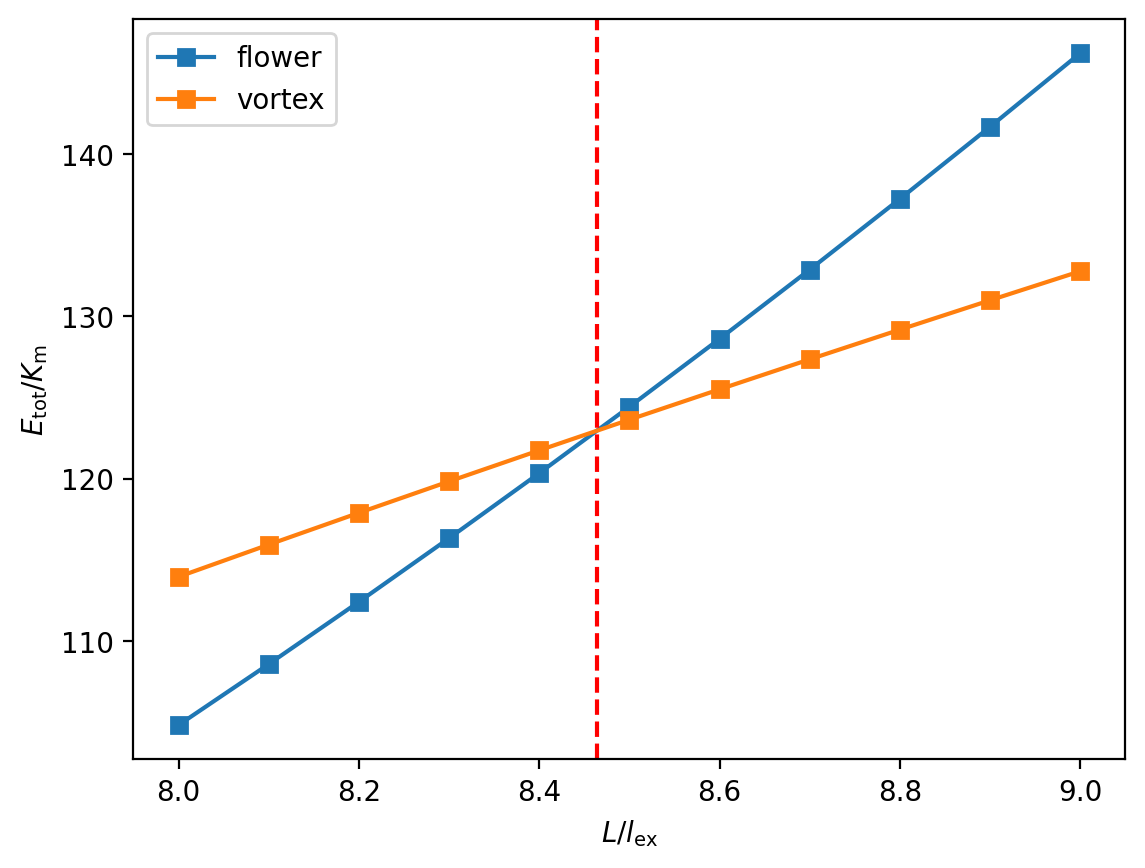

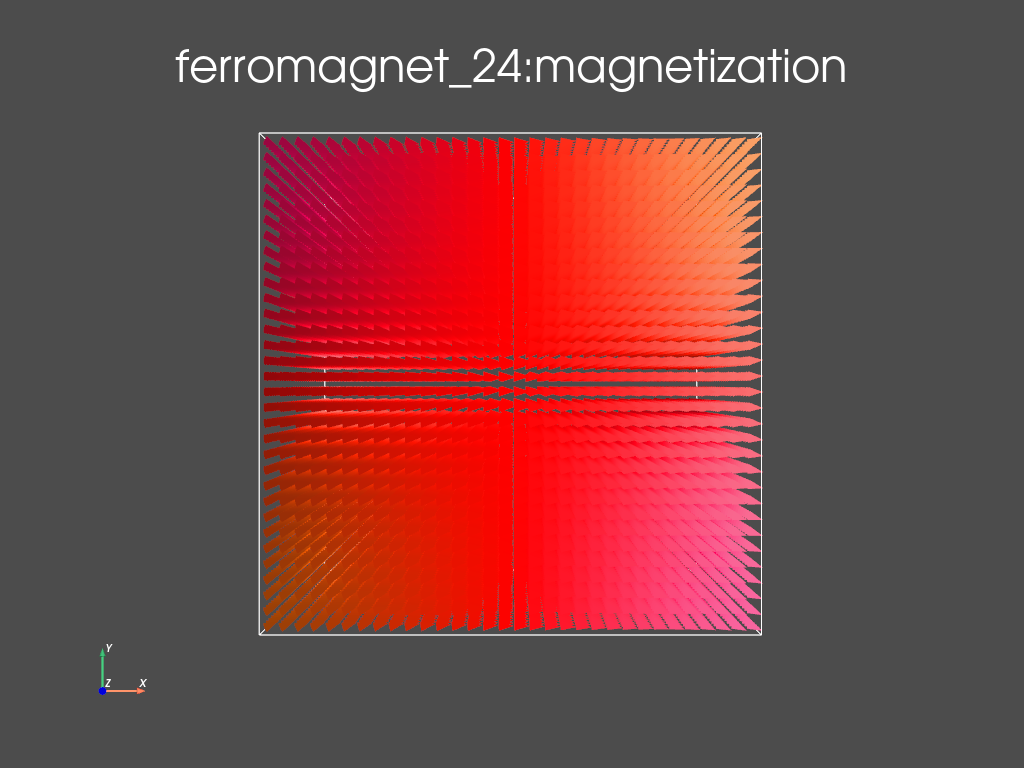

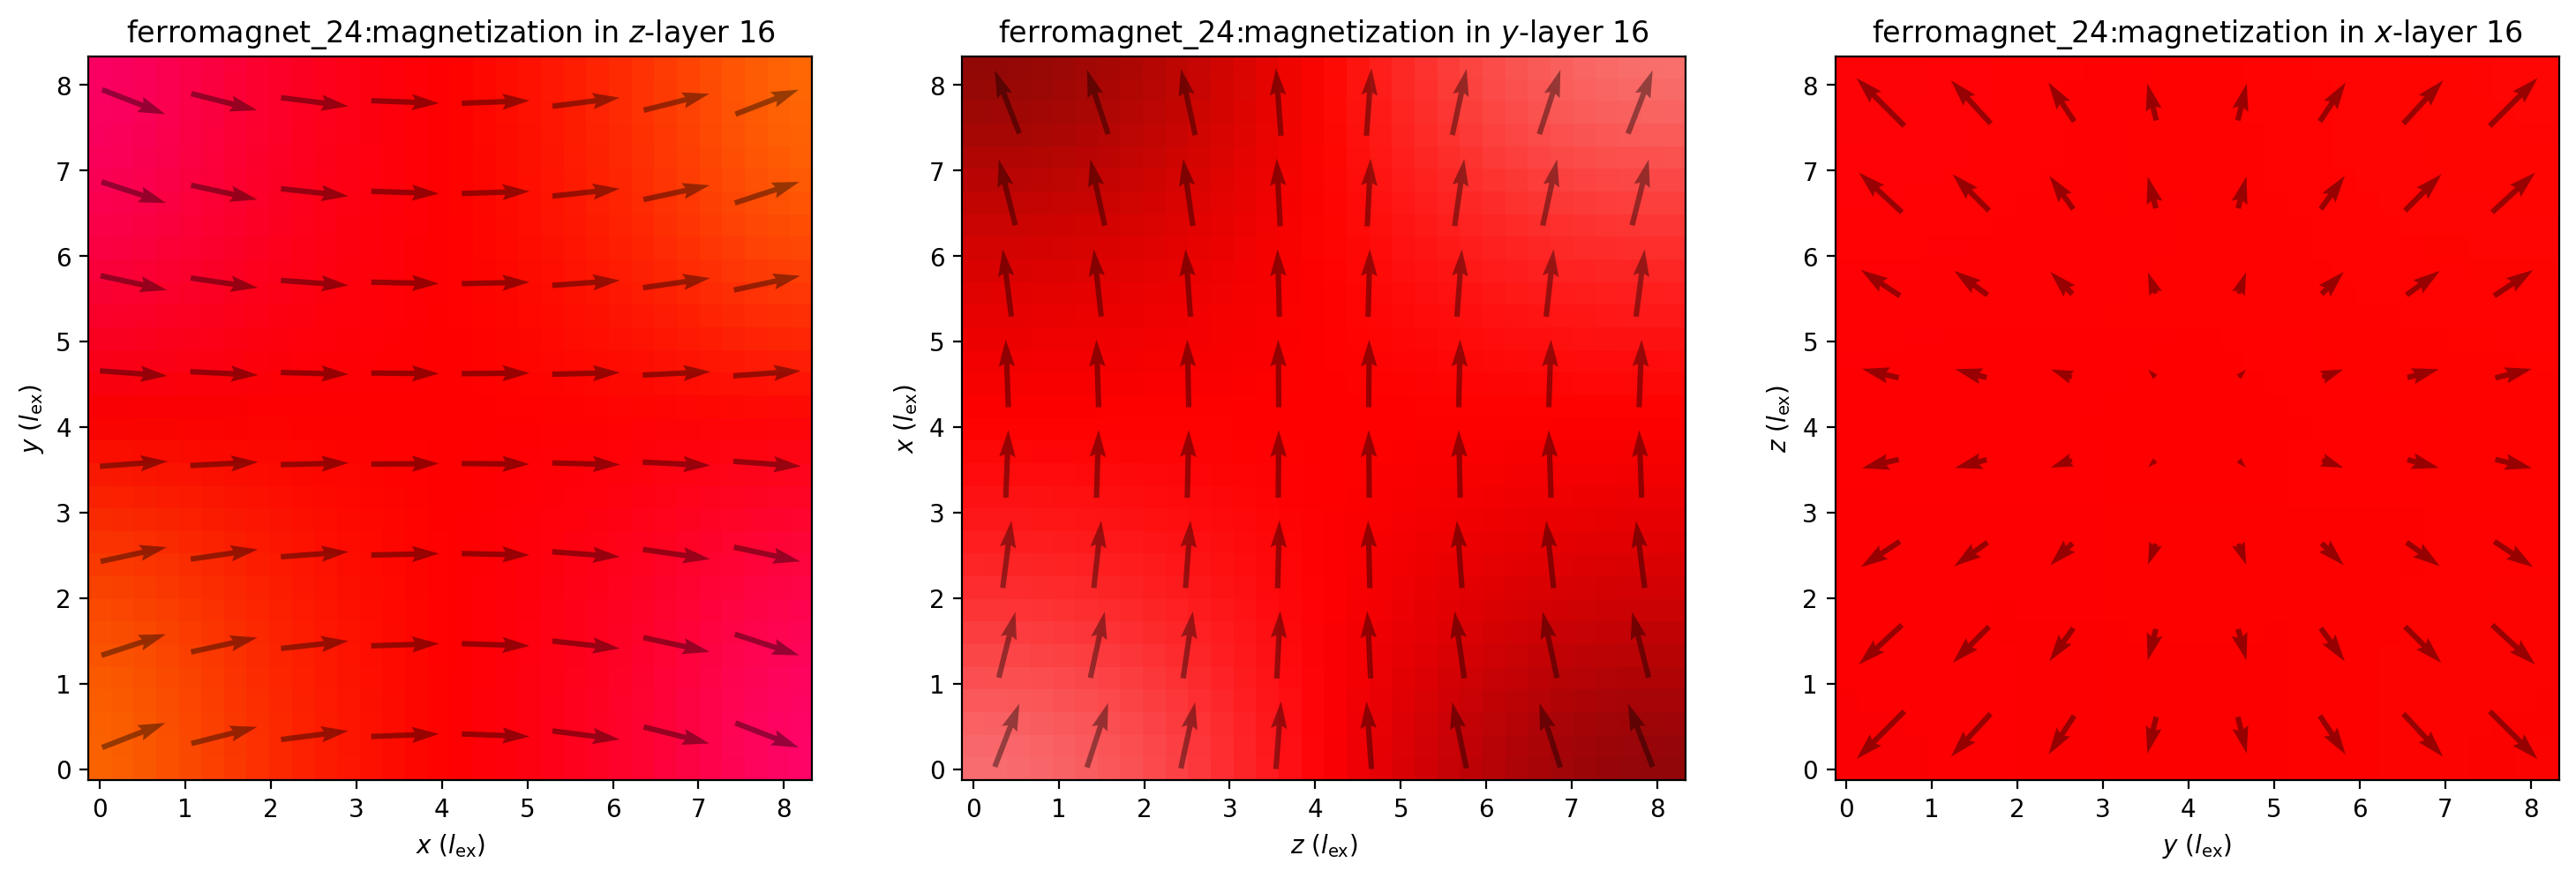

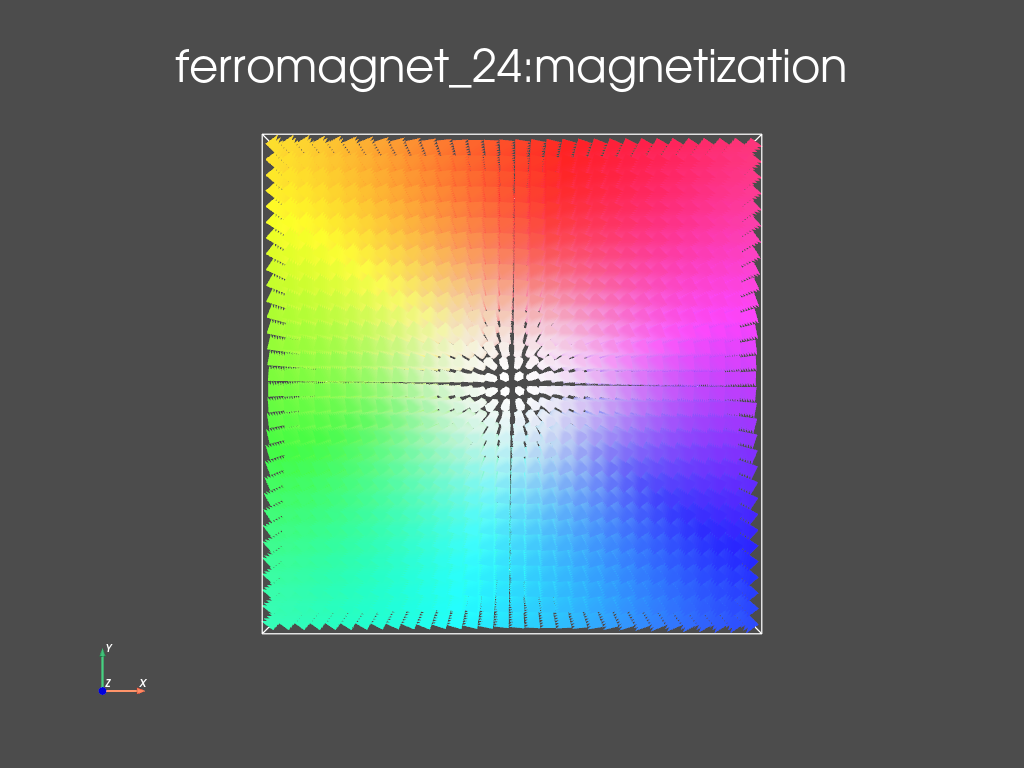

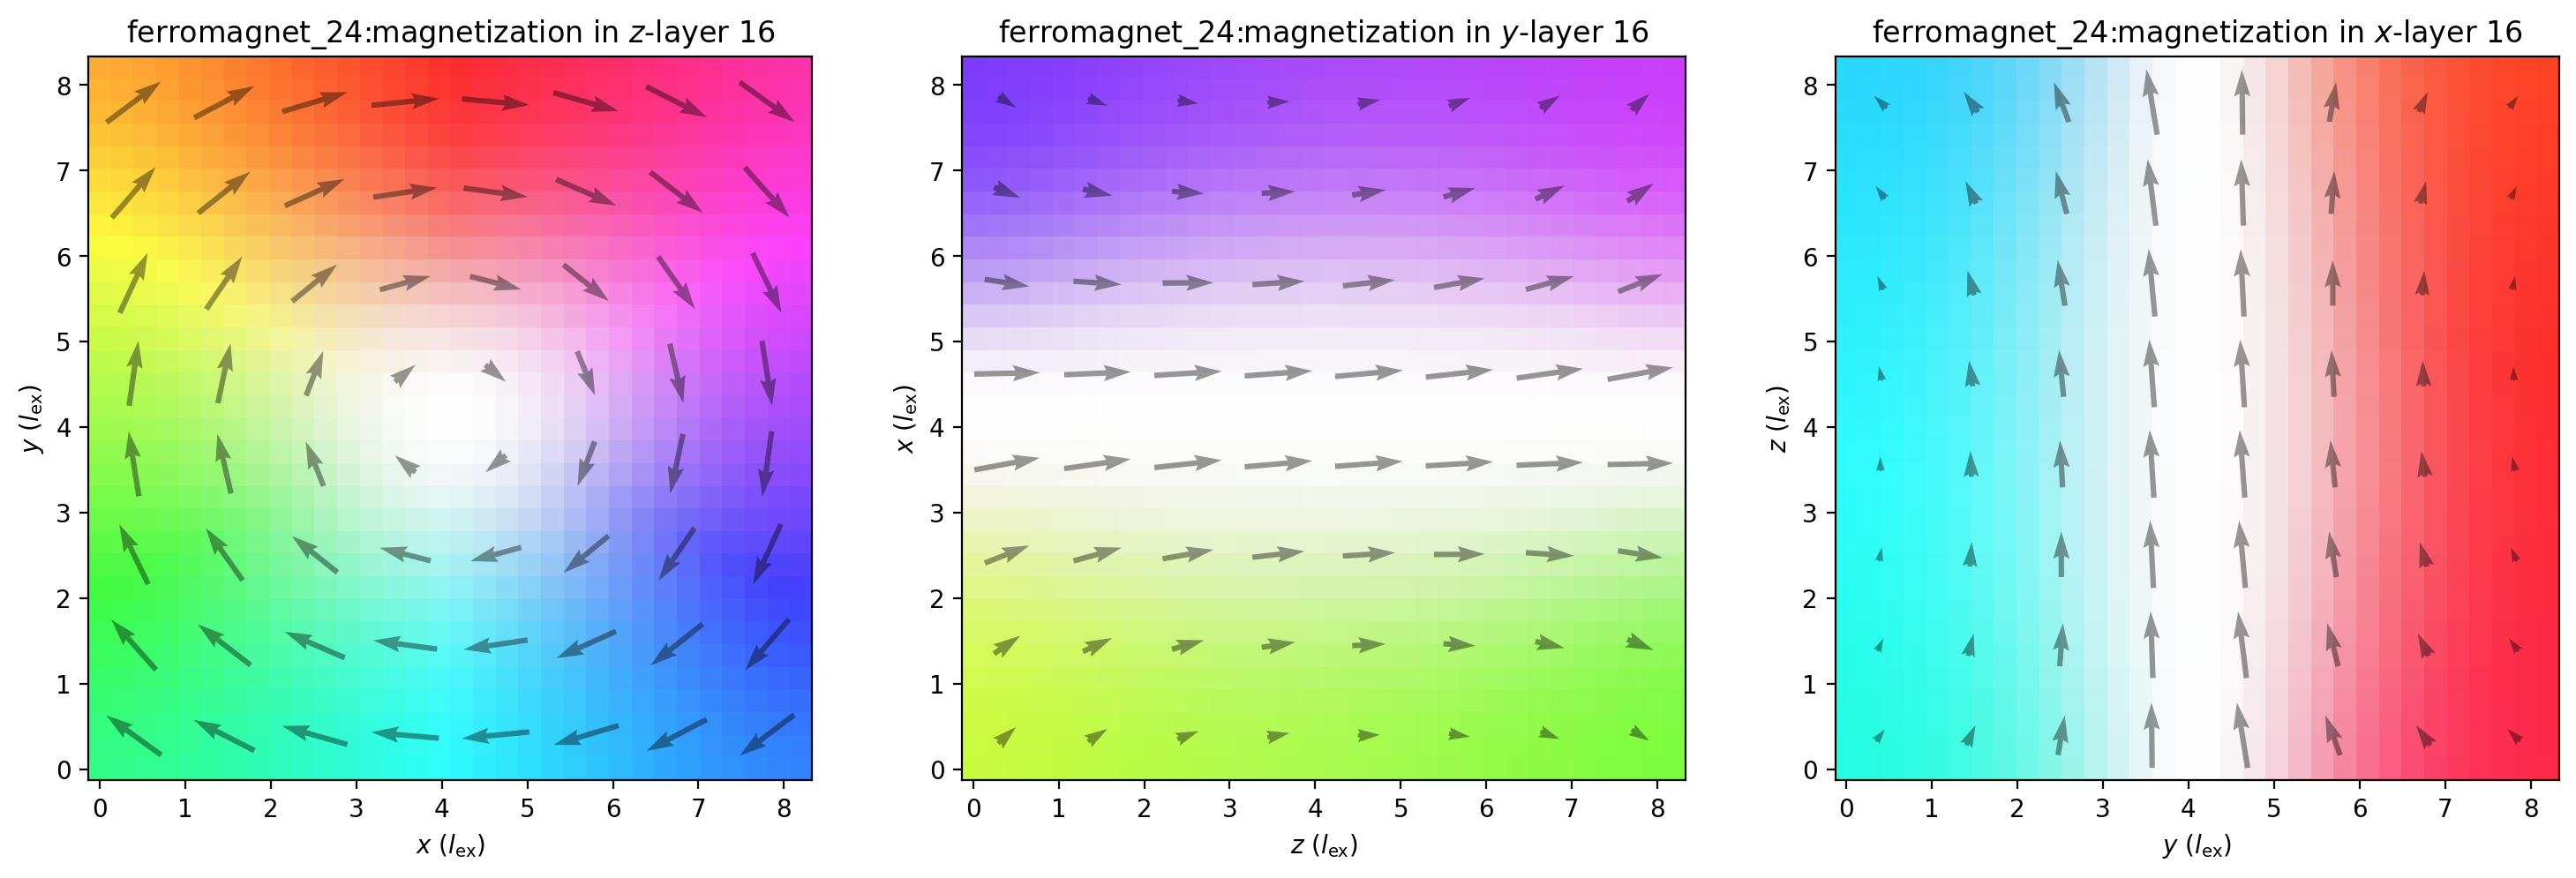

In [6]:
# This script solves micromagnetic standard problem 3. The Problem specification
# can be found on https://www.ctcms.nist.gov/~rdm/mumag.org.html
# Only flower and vortex states are studied, but the mumax³ paper shows there to
# be a twisted flower state and a canted vortex state as well.
# https://doi.org/10.1063/1.4899186

import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util import plot_field, show_field_3D, vortex

plt.rcParams['figure.dpi'] = 200

# A cube with edge length, L, expressed in units lex = (A/Km)1/2
# where Km is a magnetostatic energy density, Km = 1/2 µ0 Msat² (SI)
# So we express lengths in 'units' l_ex and energies in 'units' Km
# by setting both to 1.
mu0 = 1.25663706212e-6
msat = np.sqrt(2/mu0)  # so Km = 1/2 µ0 Msat² = 1
aex = 1.0  # so l_ex = sqrt(aex / Km) = 1

ku1 = 0.1  # 0.1 * Km as specified
anisU = (1, 0, 0)  # switched x and z for convenience

L_min, L_max, L_step = 8.0, 9.0, 0.1  # lengths in units of exchange length l_ex
L_array = np.arange(L_min, L_max + 0.5*L_step, L_step)

N = 32  # maximum cell length of L_max/N = 0.281 l_ex

def setup_magnet(L):
    world = World(cellsize=(L/N, L/N, L/N))
    magnet = Ferromagnet(world, Grid((N, N, N)))

    magnet.msat = msat
    magnet.aex = aex
    magnet.ku1 = ku1
    magnet.anisU = anisU

    return world, magnet

flower_E_tots = []
vortex_E_tots = []
for L in tqdm(L_array):
    world, magnet = setup_magnet(L)

    # flower
    magnet.magnetization = (1, 0, 0.01)  # right, with slight symmetry breaking
    magnet.minimize()
    flower_E_tots.append(magnet.total_energy.eval())

    # vortex
    magnet.magnetization = vortex(magnet.center, L/12, -1, 1)
    magnet.minimize()
    vortex_E_tots.append(magnet.total_energy.eval())

# linearly interpolate cross-over point
E_diff = np.asarray(flower_E_tots) - np.asarray(vortex_E_tots)
i = np.where(E_diff > 0)[0][0]  # cross over index
L_cross = (L_array[i-1]*E_diff[i] - L_array[i]*E_diff[i-1]) / (E_diff[i] - E_diff[i-1])

# plot energies
fig, ax = plt.subplots()
ax.plot(L_array, flower_E_tots, marker="s", label="flower")
ax.plot(L_array, vortex_E_tots, marker="s", label="vortex")
ax.axvline(x=L_cross, ls="--", c="r")
ax.set_xlabel(r"$L/l_{\rm ex}$")
ax.set_ylabel(r"$E_{\rm tot}/K_{\rm m}$")
ax.legend()
plt.show()

# show states at phase transition
show_states = True
enable_quiver = True  #  3D plot with(out) arrows

def plot_sliced_field(qty):
    """Plot the 3 planar slices (approximately) through the middle of the cube."""
    fig, axs = plt.subplots(ncols=3, figsize=(15, 4.8))
    for i, c in enumerate("zyx"):
        plot_field(qty, ax=axs[i], arrow_size=4, out_of_plane_axis=c, layer=N//2,
                xlabel=f"${'xyz'[0-i]}$"+r" ($l_{\rm ex}$)",
                ylabel=f"${'xyz'[1-i]}$"+r" ($l_{\rm ex}$)")
    fig.tight_layout()
    plt.show()

if show_states:
    world, magnet = setup_magnet(L_cross)

    # flower
    magnet.magnetization = (1, 0, 0.01)  # right, with slight symmetry breaking
    magnet.minimize()
    show_field_3D(magnet.magnetization, enable_quiver=enable_quiver)
    plot_sliced_field(magnet.magnetization)

    # vortex
    magnet.magnetization = vortex(magnet.center, L_cross/12, -1, 1)
    magnet.minimize()
    show_field_3D(magnet.magnetization, enable_quiver=enable_quiver)
    plot_sliced_field(magnet.magnetization)